# RNN-Based Text Classification Using AG News Dataset
### Building and Comparing RNN, LSTM, GRU, and Bi-LSTM Models for News Topic Classification

This notebook classifies news articles from the **AG News** dataset into four categories (World, Sports, Business, Sci/Tech). It builds and compares four sequence models (Simple RNN, LSTM, GRU and Bi-LSTM) and studies the effect of gradient clipping.

---

## Task 1: Load and Explore the Dataset

In this task, the AG News dataset is loaded using the Hugging Face `datasets` library and explored by examining its structure, size, sample articles and class distribution.

In [1]:
# Install the Hugging Face datasets library (needed only once)
!pip3 install datasets

Defaulting to user installation because normal site-packages is not writeable
     |████████████████████████████████| 515 kB 3.1 MB/s eta 0:00:01
     |████████████████████████████████| 31.2 MB 13.1 MB/s eta 0:00:01
     |████████████████████████████████| 119 kB 9.0 MB/s eta 0:00:01
     |████████████████████████████████| 625 kB 10.3 MB/s eta 0:00:01
     |████████████████████████████████| 80 kB 10.6 MB/s eta 0:00:01
     |████████████████████████████████| 133 kB 13.2 MB/s eta 0:00:01
     |████████████████████████████████| 200 kB 4.8 MB/s eta 0:00:01
     |████████████████████████████████| 499 kB 5.1 MB/s eta 0:00:01
     |████████████████████████████████| 50 kB 6.5 MB/s eta 0:00:01
     |████████████████████████████████| 94 kB 5.7 MB/s eta 0:00:011
     |████████████████████████████████| 44 kB 7.1 MB/s eta 0:00:01
     |████████████████████████████████| 47 kB 4.1 MB/s eta 0:00:01
     |████████████████████████████████| 3.6 MB 11.4 MB/s eta 0:00:01
     |██████████████████████████████

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from datasets import load_dataset

# Load the AG News dataset
dataset = load_dataset("ag_news")

# Class names, in label order (0, 1, 2, 3)
class_names = dataset["train"].features["label"].names
print("Class names:", class_names)

Class names: ['World', 'Sports', 'Business', 'Sci/Tech']


### 1. Display the Dataset Structure

The dataset is organized as a `DatasetDict` containing a training split and a test split. Each record has two fields: `text` (the news article) and `label` (the category as an integer).

In [6]:
# Overall structure: splits, columns and number of rows
print("Dataset structure:")
print(dataset)

# Feature types for each column
print("\nFeatures:")
print(dataset["train"].features)

Dataset structure:
DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 120000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 7600
    })
})

Features:
{'text': Value('string'), 'label': ClassLabel(names=['World', 'Sports', 'Business', 'Sci/Tech'])}


### 2. Number of Training and Test Samples

In [7]:
# Number of samples in each split
num_train = len(dataset["train"])
num_test = len(dataset["test"])

print("Number of training samples:", num_train)
print("Number of test samples    :", num_test)
print("Total samples             :", num_train + num_test)

Number of training samples: 120000
Number of test samples    : 7600
Total samples             : 127600


### 3. Display 5 Sample News Articles with Their Labels

Five articles are picked at random from the training set (with a fixed seed so the selection is reproducible). Each label is shown as both its integer value and its category name.

In [8]:
# Pick 5 random training articles (fixed seed for reproducibility)
rng = np.random.default_rng(42)
sample_indices = rng.choice(num_train, size=5, replace=False)

for i, idx in enumerate(sample_indices, start=1):
    record = dataset["train"][int(idx)]
    label_id = record["label"]
    print(f"Sample {i}")
    print(f"Label : {label_id} ({class_names[label_id]})")
    print(f"Text  : {record['text']}")
    print("-" * 80)

Sample 1
Label : 2 (Business)
Text  : S P Lowers Merck Debt Rating Amid Vioxx Concern A third major debt ratings agency has stripped Merck  #38; Co. of its top credit grade, lowering the drug maker's classification by three notches amid concerns stemming from its recall of the arthritis drug Vioxx.
--------------------------------------------------------------------------------
Sample 2
Label : 2 (Business)
Text  : Australian PM gets election boost with surprise drop in &lt;b&gt;...&lt;/b&gt; SYDNEY : Prime Minister John Howard #39;s election campaign received a last-minute boost as new unemployment figures showed a larger than expected fall in the number of jobless, two days before an election he has fought on his economic record.
--------------------------------------------------------------------------------
Sample 3
Label : 0 (World)
Text  : Video shows UN hostages in Afghanistan Arabic TV network Al-Jazeera Sunday aired video showing three UN election workers taken hostage in Afgh

### 4. Check the Distribution of All 4 Classes

The number of articles in each category is counted for both the training and test sets, with percentages, to check whether the classes are balanced.

In [9]:
# Convert the splits to pandas DataFrames for easy counting
train_df = dataset["train"].to_pandas()
test_df = dataset["test"].to_pandas()

# Count samples per class
train_counts = train_df["label"].value_counts().sort_index()
test_counts = test_df["label"].value_counts().sort_index()

# Build a class distribution table
distribution_table = pd.DataFrame({
    "Label": train_counts.index,
    "Category": [class_names[i] for i in train_counts.index],
    "Train Count": train_counts.values,
    "Train %": (train_counts.values / num_train * 100).round(2),
    "Test Count": test_counts.values,
    "Test %": (test_counts.values / num_test * 100).round(2),
})

print("Class distribution table:")
display(distribution_table)

Class distribution table:


,Label,Category,Train Count,Train %,Test Count,Test %
0,0,World,30000,25.0,1900,25.0
1,1,Sports,30000,25.0,1900,25.0
2,2,Business,30000,25.0,1900,25.0
3,3,Sci/Tech,30000,25.0,1900,25.0


### 5. Plot the Class Distribution

Bar charts show the number of samples in each category for the training and test sets.

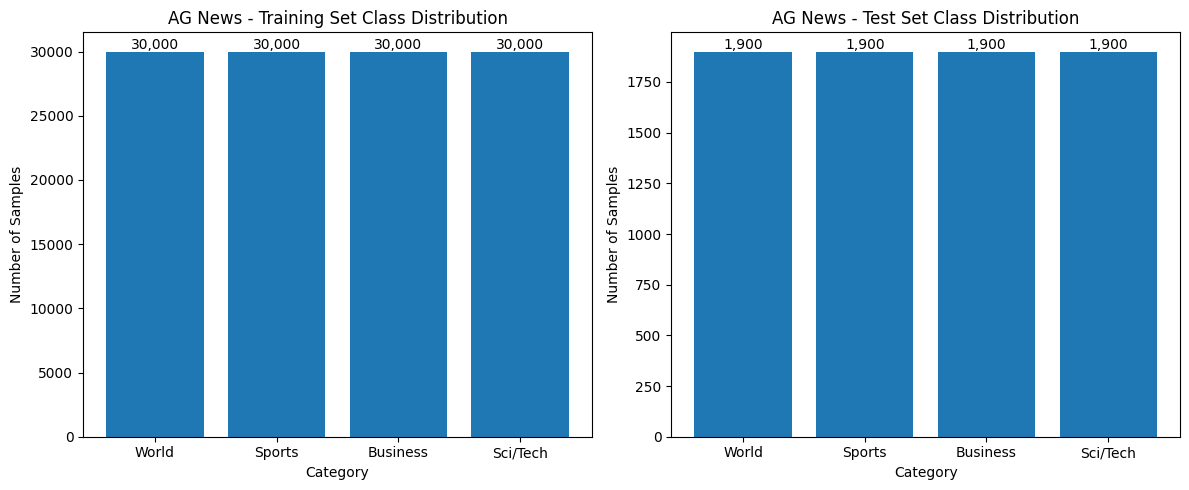

In [10]:
# Plot class distribution for training and test sets side by side
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Training set
axes[0].bar(class_names, train_counts.values)
axes[0].set_title("AG News - Training Set Class Distribution")
axes[0].set_xlabel("Category")
axes[0].set_ylabel("Number of Samples")
for i, count in enumerate(train_counts.values):
    axes[0].text(i, count, f"{count:,}", ha="center", va="bottom")

# Test set
axes[1].bar(class_names, test_counts.values)
axes[1].set_title("AG News - Test Set Class Distribution")
axes[1].set_xlabel("Category")
axes[1].set_ylabel("Number of Samples")
for i, count in enumerate(test_counts.values):
    axes[1].text(i, count, f"{count:,}", ha="center", va="bottom")

plt.tight_layout()
plt.show()

### Observations: Task 1

- **Dataset structure:** AG News is a `DatasetDict` with a `train` split and a `test` split. Each record has two fields: `text` (a string) and `label` (a `ClassLabel` with 4 categories: World, Sports, Business, Sci/Tech).
- **Size:** The training set contains **120,000** articles and the test set contains **7,600** articles, 127,600 in total. The dataset is large enough to train sequence models from scratch.
- **Class balance:** The dataset is **perfectly balanced**. Every class has 30,000 training samples and 1,900 test samples, which is exactly 25% of each split. No class is over- or under-represented.
- **Implication for evaluation:** Because the classes are balanced, a model guessing at random would score about 25%, and **accuracy is a fair and sufficient metric** for comparing models. Techniques for handling class imbalance, such as class weights or macro F1, are not needed here.
- **Nature of the text:** Each sample combines a short headline with a one- or two-sentence description, so the articles are short. The sample articles are clearly distinguishable by topic (for example, debt ratings and unemployment figures for Business, hostages and elections for World, and a mobile phone system for Sci/Tech).
- **Data quality note:** Some samples contain leftover HTML and encoding artifacts, such as `#39;` (an apostrophe), `#38;` (an ampersand) and `&lt;b&gt;...&lt;/b&gt;`. These will be tokenized like ordinary words, so they are worth keeping in mind during text preprocessing in Task 2.